In [1]:
import json
import glob
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

In [2]:
raw_files = sorted(Path("data/raw").glob("*/london_*.json"))
print(raw_files)

with open(raw_files[-1], encoding="utf-8") as f:
    payload = json.load(f)

print(payload.keys())
print(payload["hourly"].keys())
print(len(payload["hourly"]["time"]))

[PosixPath('data/raw/2026-11-07/london_20261107T185414.json'), PosixPath('data/raw/2026-11-07/london_20261107T185957.json'), PosixPath('data/raw/2026-11-07/london_20261107T190131.json'), PosixPath('data/raw/2026-11-07/london_20261107T201728.json'), PosixPath('data/raw/2026-11-07/london_20261107T202049.json'), PosixPath('data/raw/2026-11-07/london_20261107T202050.json')]
dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])
dict_keys(['time', 'temperature_2m', 'relative_humidity_2m', 'apparent_temperature', 'precipitation', 'wind_speed_10m', 'weather_code'])
48


In [3]:
def flatten(payload: dict, city_name: str) -> pd.DataFrame:
    df = pd.DataFrame(payload["hourly"])
    df["city"] = city_name
    df["latitude"] = payload["latitude"]
    df["longitude"] = payload["longitude"]
    return df

In [4]:
frames = []
for path in sorted(glob.glob("data/raw/*/*.json")):
    with open(path, encoding="utf-8") as f:
        payload = json.load(f)
    city = Path(path).name.split("_")[0].capitalize()
    frames.append(flatten(payload, city))

df = pd.concat(frames, ignore_index=True)
print("duplicates before drop:", df.duplicated(subset=["city", "time"]).sum())

df = df.drop_duplicates(subset=["city", "time"], keep="last")
print(df.shape)
print(df["city"].value_counts())

duplicates before drop: 1152
(240, 10)
city
Birmingham    48
Cardiff       48
Edinburgh     48
London        48
Manchester    48
Name: count, dtype: int64


In [5]:
print(df.shape)
print(df.dtypes)
df.head()

(240, 10)
time                        str
temperature_2m          float64
relative_humidity_2m      int64
apparent_temperature    float64
precipitation           float64
wind_speed_10m          float64
weather_code              int64
city                        str
latitude                float64
longitude               float64
dtype: object


,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude
240,2026-11-06T00:00,8.1,78,5.5,0.0,8.3,3,Birmingham,52.488224,-1.909378
241,2026-11-06T01:00,8.0,78,5.5,0.0,7.9,3,Birmingham,52.488224,-1.909378
242,2026-11-06T02:00,8.0,79,5.3,0.0,9.4,3,Birmingham,52.488224,-1.909378
243,2026-11-06T03:00,8.0,80,5.5,0.0,8.6,3,Birmingham,52.488224,-1.909378
244,2026-11-06T04:00,8.0,80,5.6,0.0,8.3,3,Birmingham,52.488224,-1.909378


In [6]:
print(df.isna().sum())

time                    0
temperature_2m          0
relative_humidity_2m    0
apparent_temperature    0
precipitation           0
wind_speed_10m          0
weather_code            0
city                    0
latitude                0
longitude               0
dtype: int64


Chart

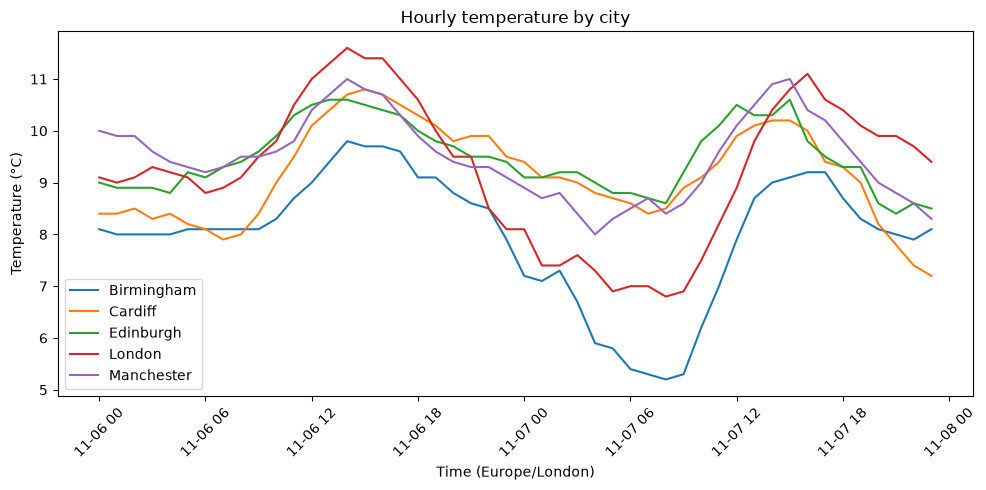

In [7]:
df["time_dt"] = pd.to_datetime(df["time"])

fig, ax = plt.subplots(figsize=(10, 5))
for city, g in df.groupby("city"):
    ax.plot(g["time_dt"], g["temperature_2m"], label=city)

ax.set_xlabel("Time (Europe/London)")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Hourly temperature by city")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Final 5 Key Findings
1. Temperature Variation: All five cities experienced temperature fluctuations over the observation period, with temperature ranges between 2.6°C and 4.8°C. London recorded the largest variation (4.8°C), while Edinburgh had the smallest (2.6°C).

2. Birmingham's Overnight Temperature Drop: Birmingham recorded the lowest minimum temperature across the five cities during the early morning of 7 November. However, London had the largest overall temperature range, so Birmingham's drop should not be described as the largest without further analysis.

3. London Recorded the Highest Temperature: London reached the highest recorded temperature of 11.6°C on 6 November, followed by a noticeable decline overnight.

4. Temperature Consistency Across Cities: Edinburgh showed the most stable temperature pattern, with the smallest overall temperature range of 2.6°C, compared with Birmingham (4.6°C), Cardiff (3.4°C), Manchester (3.0°C) and London (4.8°C).

5. Data Quality and Reliability: Although the dataset contains no missing values 1,152 of 1,392 rows (82.8%) are duplicates
240 unique city-hour rows remain after removal